### Truncation thresholds tutorial

This notebooks provides the code to visualize what modes are being truncated based on the input threshold.

In [2]:
import numpy as np
import matplotlib.gridspec as gridspec
from lsst.ts.ofc import OFC, OFCData, SensitivityMatrix
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colors, cm

%load_ext autoreload
%autoreload 2

%matplotlib inline

Initialize below the sensitivity matrix of interest. It returns the rescaled (normalized) sensitivity matrix. You will need to modify this cell if you want to use other detectors than the ComCam ones. You can also modify it by setting ofc_data.zn_selected, in case not all zernikes will be used. When trying different normalization weights, you will need to re-run this notebook. 

In [16]:
#ofc_data = OFCData('lsst')
ofc_data = OFCData('lsst', config_dir='/home/r/roodman/u/LSST/packages/ts_config_mttcs/MTAOS/v8/ofc' )
dz_sensitivity_matrix = SensitivityMatrix(ofc_data)
sensor_name_list = [        
        "R00_SW0",
        "R04_SW0",
        "R40_SW0",
        "R44_SW0",
]

field_angles = [
    ofc_data.sample_points[sensor] for sensor in sensor_name_list
]
print('Field Angles = ',field_angles)  # these are the 4 corners

dz_sensitivity_matrix = SensitivityMatrix(ofc_data)
sensitivity_matrix = dz_sensitivity_matrix.evaluate(
    field_angles, 0.0
)
print('Sensitivity matrix, evaluated at corners, shape = ',sensitivity_matrix.shape)

# message from Josh: https://rubin-obs.slack.com/archives/C0ABQCZ2CMT/p1771007994250129
#
zn = np.array([4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26])


#zn_idx = np.array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
#       17, 18, 19, 20, 21, 22])

zn_idx = zn - 4

print('Normal list of Zernikes, starting from z4 = ',zn_idx)
print('Normal list of DoFs ',ofc_data.dof_idx)

sensitivity_matrix = sensitivity_matrix[:, zn_idx, :]  #use zn_idx instead of ofc_data.zn_idx

size = sensitivity_matrix.shape[2]
print('Size to reshape = ',size)

sensitivity_matrix = sensitivity_matrix.reshape((-1, size))

sensitivity_matrix = sensitivity_matrix[..., ofc_data.dof_idx]
raw_sensitivity_matrix = sensitivity_matrix.copy()
print('Reshaped Smatrix = ',sensitivity_matrix.shape)

# so what is done here is to downsample to 19 Zernikes (from 25) and then concatinate the 4 corners to get a Zernike dimension of 76

normalization_matrix = np.diag(
    ofc_data.normalization_weights[ofc_data.dof_idx]
)

print('Shape of Normalization matrix =',normalization_matrix.shape)
print('Normalization vector in DOF = ',ofc_data.normalization_weights[ofc_data.dof_idx])

sensitivity_matrix = sensitivity_matrix @ normalization_matrix

Field Angles =  [[-1.1902777777777778, -1.1902777777777778], [-1.1902777777777778, 1.1902777777777778], [1.1902777777777778, -1.1902777777777778], [1.1902777777777778, 1.1902777777777778]]
Sensitivity matrix, evaluated at corners, shape =  (4, 25, 50)
Normal list of Zernikes, starting from z4 =  [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 18 19 20 21 22]
Normal list of DoFs  [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
Size to reshape =  50
Reshaped Smatrix =  (84, 50)
Shape of Normalization matrix = (50, 50)
Normalization vector in DOF =  [6.83022266e+01 3.53387321e+00 3.53386546e+00 7.25194304e+00
 7.25197701e+00 1.04487016e+02 1.10675415e+00 1.10676354e+00
 4.96064186e-01 4.96056231e-01 3.40975927e-01 3.39386929e-01
 9.56805058e-02 7.59109020e-02 7.58649990e-02 3.14679990e-02
 2.84070213e-02 2.84230479e-02 2.52858996e-02 2.44061617e-02
 2.33615823e-02 3.80499452e-03 1.33

## explore the Smatrix and the normalization matrix

In [17]:
iz8 = 8 - 4
raw_sensitivity_matrix[iz8,1]  #M2 dx and (1,8)

np.float64(0.0006304999424283965)

In [18]:
iz4 = 4- 4
jcamdz = 5  # Cam dz and (1,4)
print(raw_sensitivity_matrix[iz4,jcamdz])
print(raw_sensitivity_matrix[iz4+23,jcamdz])
print(raw_sensitivity_matrix[iz4+23*2,jcamdz])
print(raw_sensitivity_matrix[iz4+23*3,jcamdz])

print(sensitivity_matrix[iz4,jcamdz])
print(sensitivity_matrix[iz4+23,jcamdz])
print(sensitivity_matrix[iz4+23*2,jcamdz])
print(sensitivity_matrix[iz4+23*3,jcamdz])

-0.01592839020614445
-3.3056711185131005e-09
-0.0002470564680709276
1.539728159861762e-06
-1.6643099624005515
-3.453997110667741e-07
-0.02581419313342315
0.0001608816008825594


In [19]:
labels = ['M2 dz', 'M2 dx', 'M2 dy', 'M2 rx', 'M2 ry',
         'cam dz', 'cam dx', 'cam dy', 'cam rx', 'cam ry',
         'B1,1', 'B1,2', 'B1,3', 'B1,4', 'B1,5',
         'B1,6', 'B1,7', 'B1,8', 'B1,9', 'B1,10',
         'B1,11', 'B1,12', 'B1,13', 'B1,14', 'B1,15',
         'B1,16', 'B1,17', 'B1,18', 'B1,19', 'B1,20',
         'B2,1', 'B2,2', 'B2,3', 'B2,4', 'B2,5',
         'B2,6', 'B2,7', 'B2,8', 'B2,9', 'B2,10',
         'B2,11', 'B2,12', 'B2,13', 'B2,14', 'B2,15',
         'B2,16', 'B2,17', 'B2,18', 'B2,19', 'B2,20'
         ]

In [20]:
sensitivity_matrix.shape

(84, 50)

Text(0.5, 0, 'Sensitivity Matrix (w/ normalization) Coefficient magnitude')

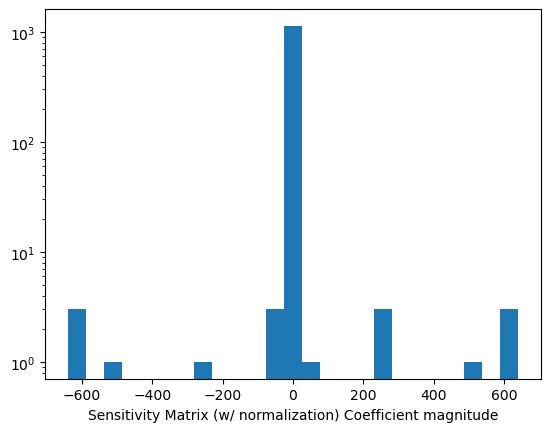

In [21]:
f,ax = plt.subplots(1,1)
nZs = 23
_ = ax.hist(sensitivity_matrix[0:nZs,:].flatten(),bins=25)
ax.set_yscale('log')
ax.set_xlabel('Sensitivity Matrix (w/ normalization) Coefficient magnitude')

Text(0.5, 0.98, 'Sensitivity Matrix (w/ normalization) Coefficient magnitude')

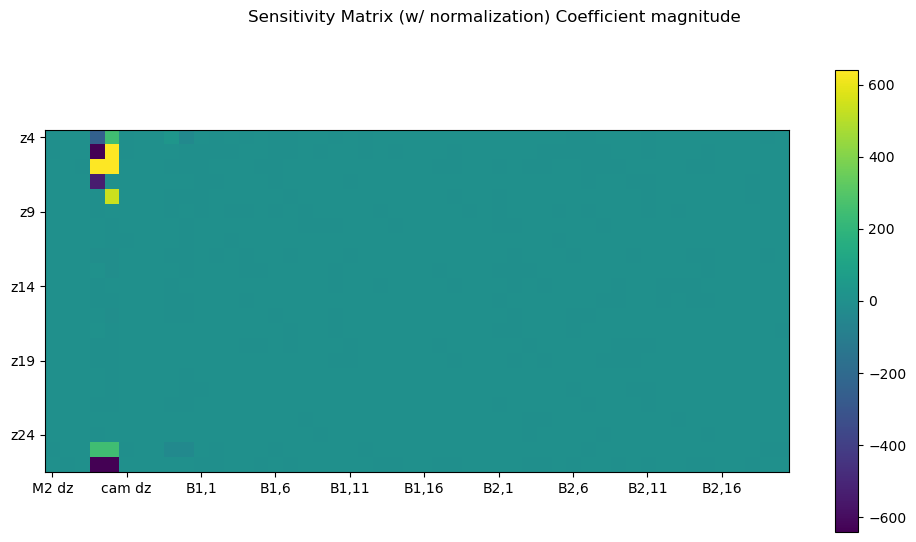

In [22]:
f,ax = plt.subplots(1,1,figsize=(12,6))
nZs = 23
r = ax.imshow(sensitivity_matrix[0:nZs,:])
tt = ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 35, 40, 45], [labels[0], labels[5], labels[10], labels[15], labels[20], labels[25], labels[30], labels[35], labels[40],labels[45]])
tt = ax.set_yticks([0,5,10,15,20],['z4','z9','z14','z19','z24'])
f.colorbar(r)
f.suptitle('Sensitivity Matrix (w/ normalization) Coefficient magnitude')

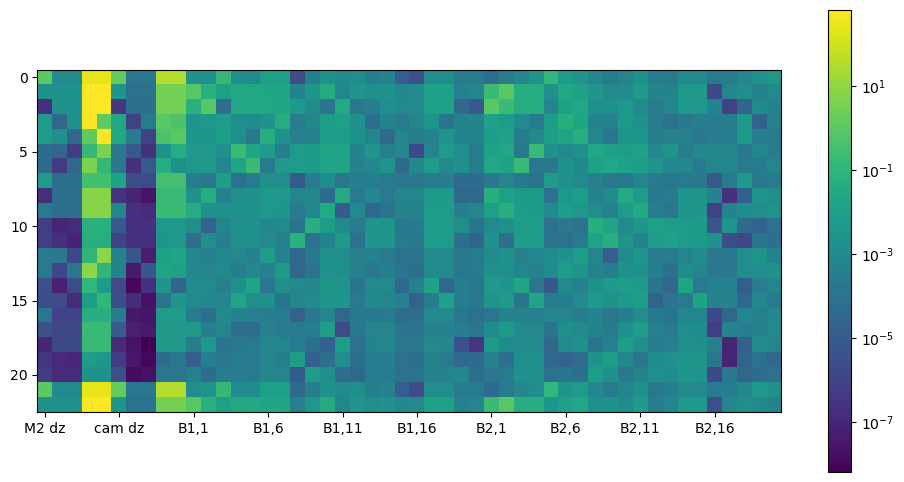

In [23]:
f,ax = plt.subplots(1,1,figsize=(12,6))
nZs = 23
r = ax.imshow(np.abs(sensitivity_matrix[0:nZs,:]),norm=colors.LogNorm())
tt = ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 35, 40, 45], [labels[0], labels[5], labels[10], labels[15], labels[20], labels[25], labels[30], labels[35], labels[40],labels[45]])
f.colorbar(r)


Text(0.5, 0.98, 'Raw Sensitivity Matrix (w/o normalization) Coefficient magnitude')

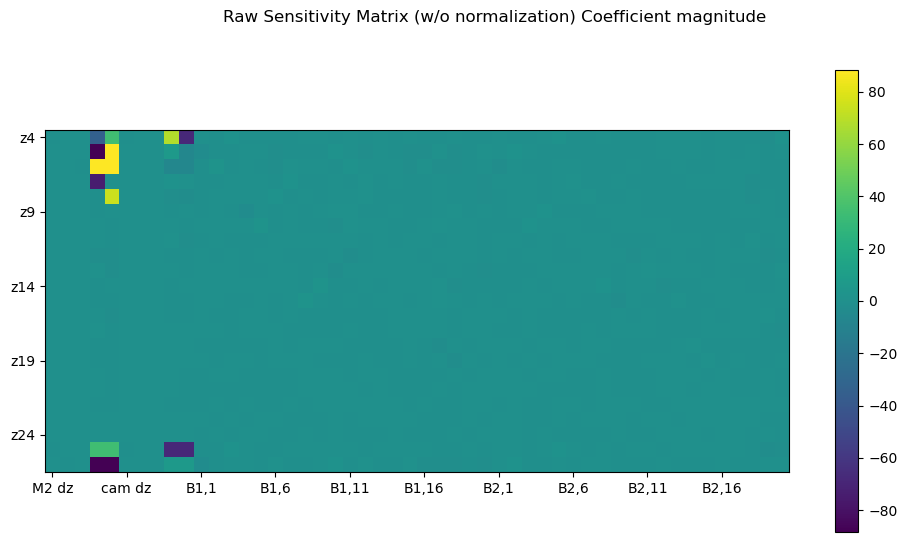

In [24]:
f,ax = plt.subplots(1,1,figsize=(12,6))
nZs = 23
r = ax.imshow(raw_sensitivity_matrix[0:nZs,:])
tt = ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 35, 40, 45], [labels[0], labels[5], labels[10], labels[15], labels[20], labels[25], labels[30], labels[35], labels[40],labels[45]])
tt = ax.set_yticks([0,5,10,15,20],['z4','z9','z14','z19','z24'])
f.colorbar(r)
f.suptitle('Raw Sensitivity Matrix (w/o normalization) Coefficient magnitude')

Text(0.5, 0.98, 'Sensitivity Matrix (w/ normalization) Coefficient magnitude')

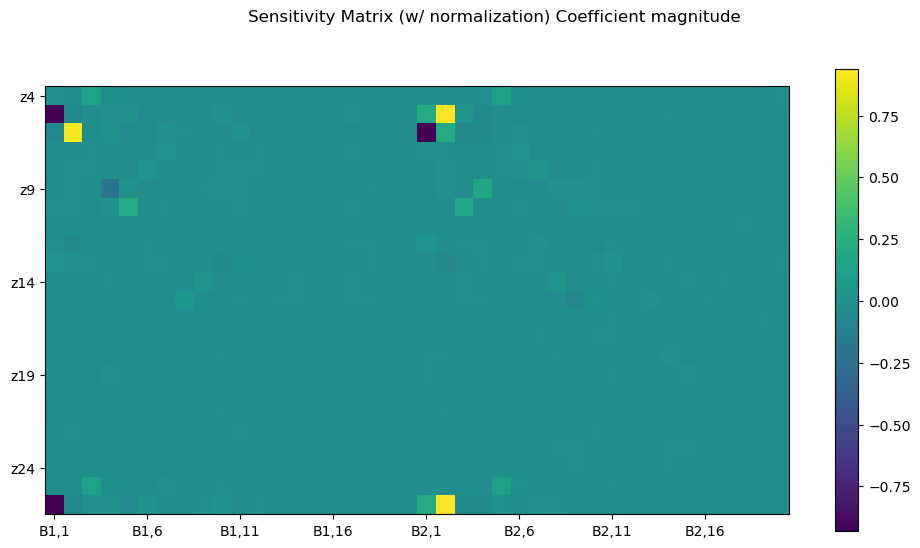

In [25]:
f,ax = plt.subplots(1,1,figsize=(12,6))
nZs = 23
r = ax.imshow(sensitivity_matrix[0:nZs,10:])
tt = ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 35], [labels[10], labels[15], labels[20], labels[25], labels[30], labels[35], labels[40],labels[45]])
tt = ax.set_yticks([0,5,10,15,20],['z4','z9','z14','z19','z24'])
f.colorbar(r)
f.suptitle('Sensitivity Matrix (w/ normalization) Coefficient magnitude')

Below the characteristic modes given the normalization weights used are plotted on the left. On the right, is the singular values for each of them along with the cutoff. One can set the cutoff by number or by value.

<>:41: SyntaxWarning: invalid escape sequence '\s'
<>:41: SyntaxWarning: invalid escape sequence '\s'
<>:41: SyntaxWarning: invalid escape sequence '\s'
<>:41: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_593/242642600.py:41: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])
/tmp/ipykernel_593/242642600.py:41: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])


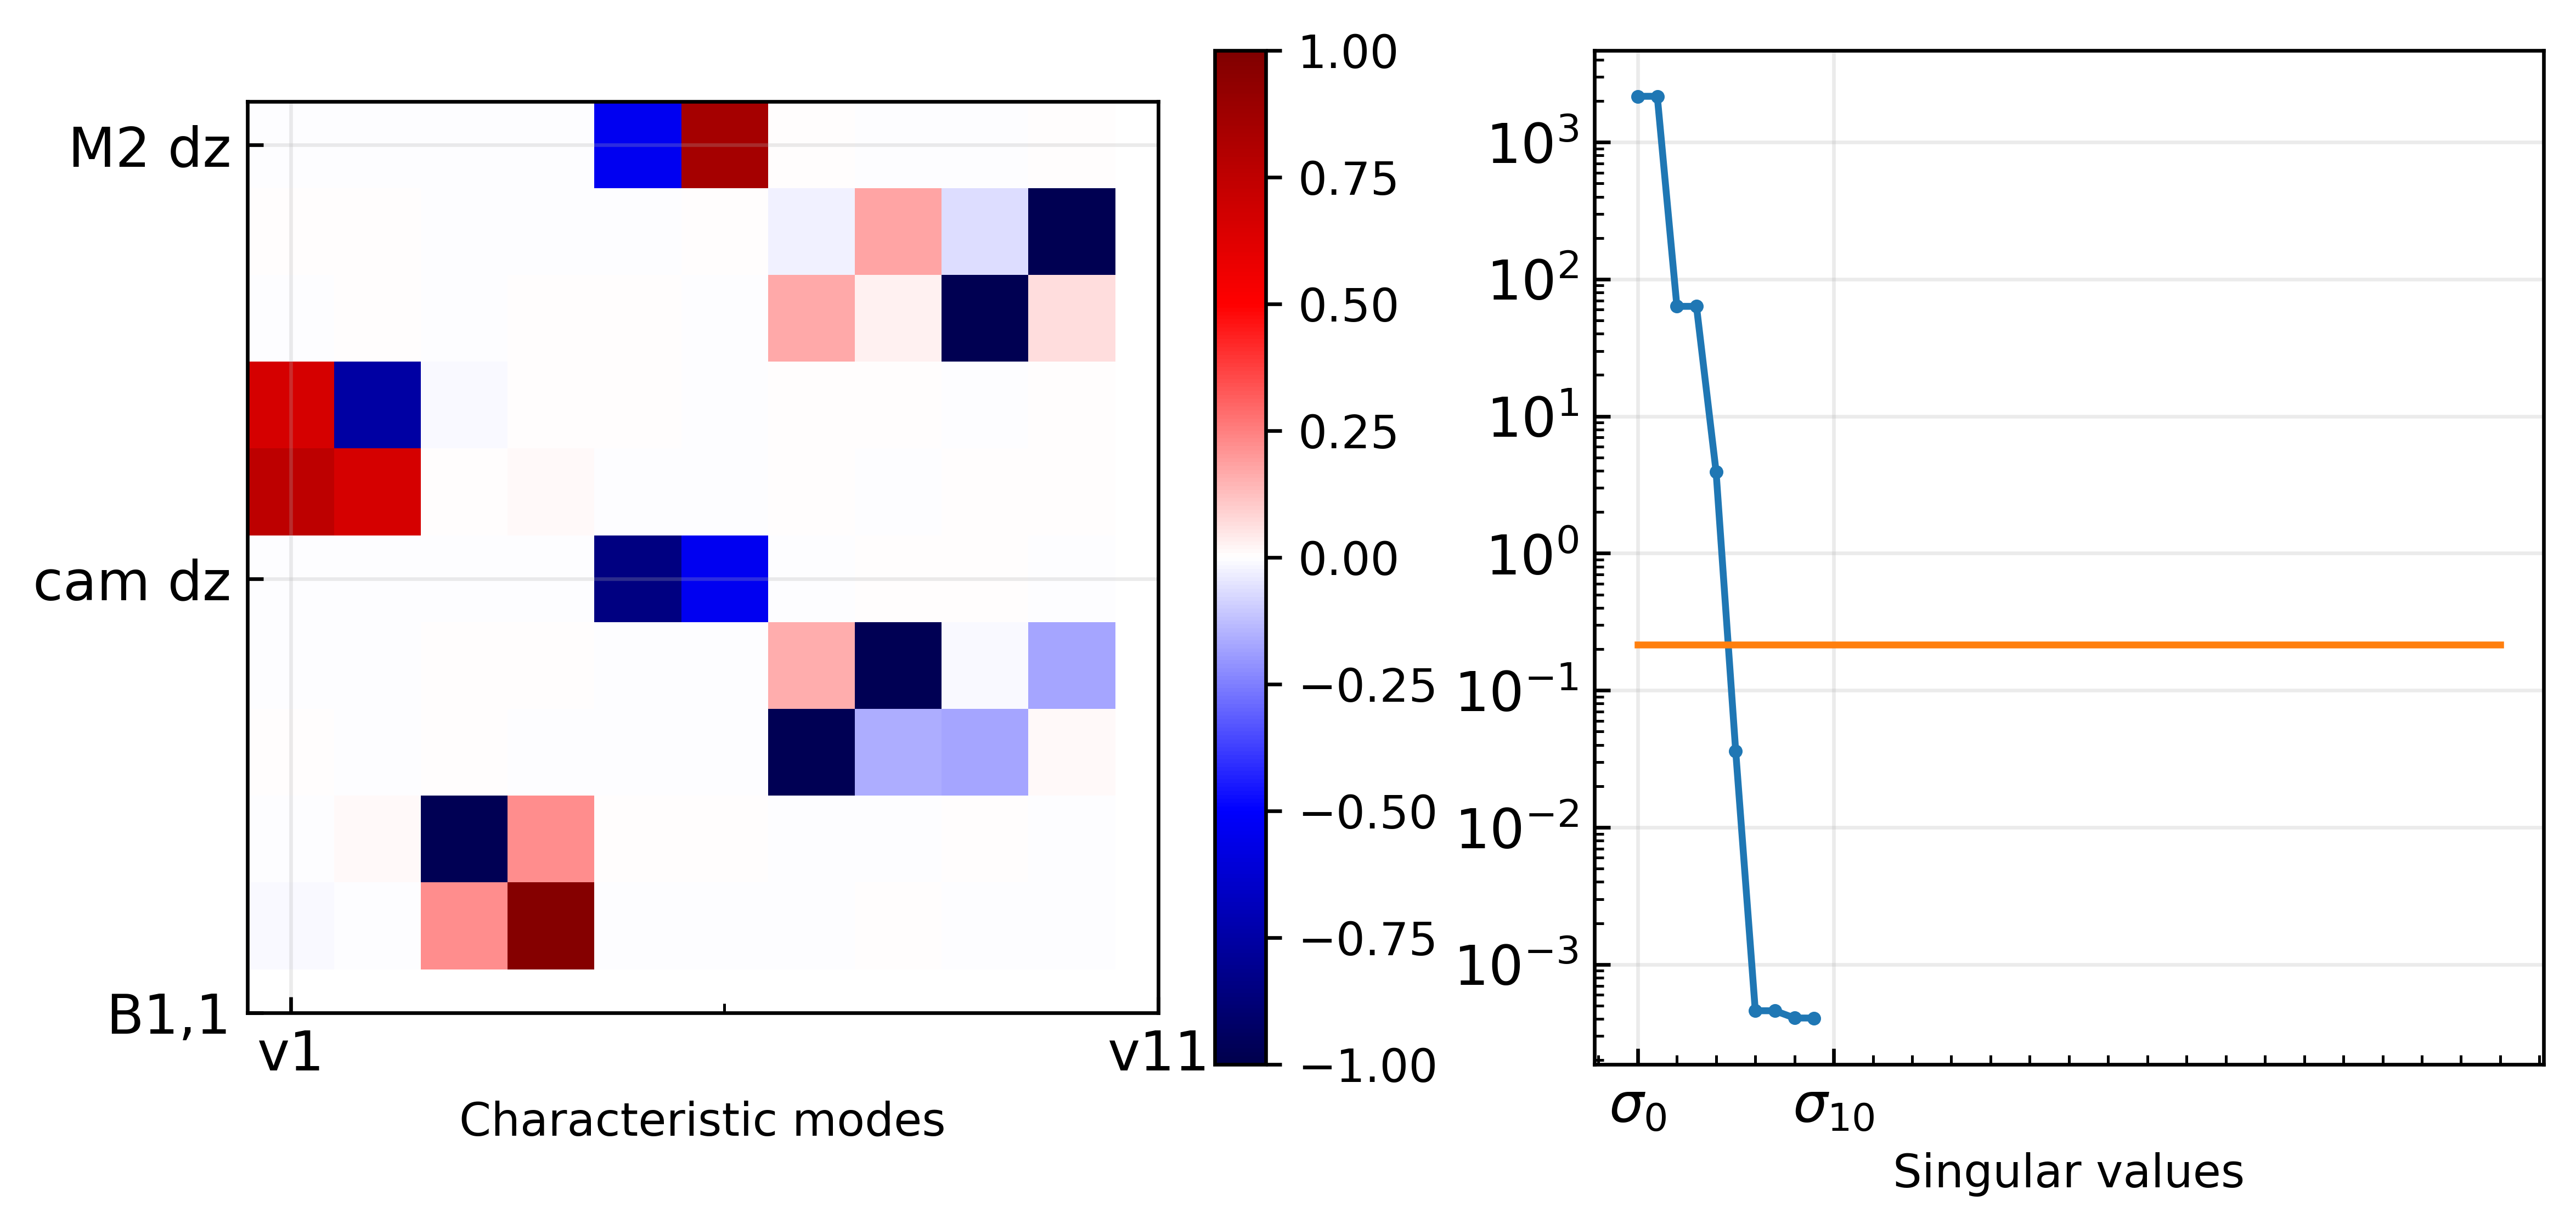

In [29]:
labels = ['M2 dz', 'M2 dx', 'M2 dy', 'M2 rx', 'M2 ry',
         'cam dz', 'cam dx', 'cam dy', 'cam rx', 'cam ry',
         'B1,1', 'B1,2', 'B1,3', 'B1,4', 'B1,5',
         'B1,6', 'B1,7', 'B1,8', 'B1,9', 'B1,10',
         'B1,11', 'B1,12', 'B1,13', 'B1,14', 'B1,15',
         'B1,16', 'B1,17', 'B1,18', 'B1,19', 'B1,20',
         'B2,1', 'B2,2', 'B2,3', 'B2,4', 'B2,5',
         'B2,6', 'B2,7', 'B2,8', 'B2,9', 'B2,10',
         'B2,11', 'B2,12', 'B2,13', 'B2,14', 'B2,15',
         'B2,16', 'B2,17', 'B2,18', 'B2,19', 'B2,20'
         ]
u, s, vh = np.linalg.svd(sensitivity_matrix[:,  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]], full_matrices=True)
v = vh.T

s_use10 = s
v_use10 = v
fig = plt.figure(figsize=(9, 4), dpi=600)
gs = gridspec.GridSpec(1,2, width_ratios=[1.2,1])
a0 = plt.subplot(gs[0])
a1 = plt.subplot(gs[1])

r = a0.imshow(v, cmap = 'seismic', vmin = -1, vmax = 1)

a0.set_yticks([0, 5, 10], [labels[0], labels[5], labels[10]])
a0.set_xticks([0, 10], ['v1', 'v11'])
fig.colorbar(r)
a0.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks
a0.xaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.yaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.set_xlabel('Characteristic modes')
a0.grid(alpha=0.25)
a0.tick_params(direction = 'in', labelsize=12)


a1.semilogy(s, '.-', markersize=4)
#truncate_index = 25
#cutoff =  0.85 * s[truncate_index - 1] / np.max(s)
#print(cutoff)
cutoff = 1.e-4
a1.semilogy(np.max(s)*cutoff*np.ones(45))
a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])
a1.set_xlabel('Singular values')
a1.grid(alpha=0.25)
a1.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks

a1.xaxis.set_minor_locator(ticker.AutoMinorLocator())  # Auto set minor ticks on x-axis

fig.savefig('aos_charmodes_use10.png')

# try with the usual 22 DOFs 

In [59]:
listOfDofs = list(range(0,16+1)) + list(range(30,34+1))
print(listOfDofs)
print(len(listOfDofs))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 30, 31, 32, 33, 34]
22


<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_593/1454952726.py:44: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_1$', '$\sigma_{11}$'])
/tmp/ipykernel_593/1454952726.py:44: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_1$', '$\sigma_{11}$'])


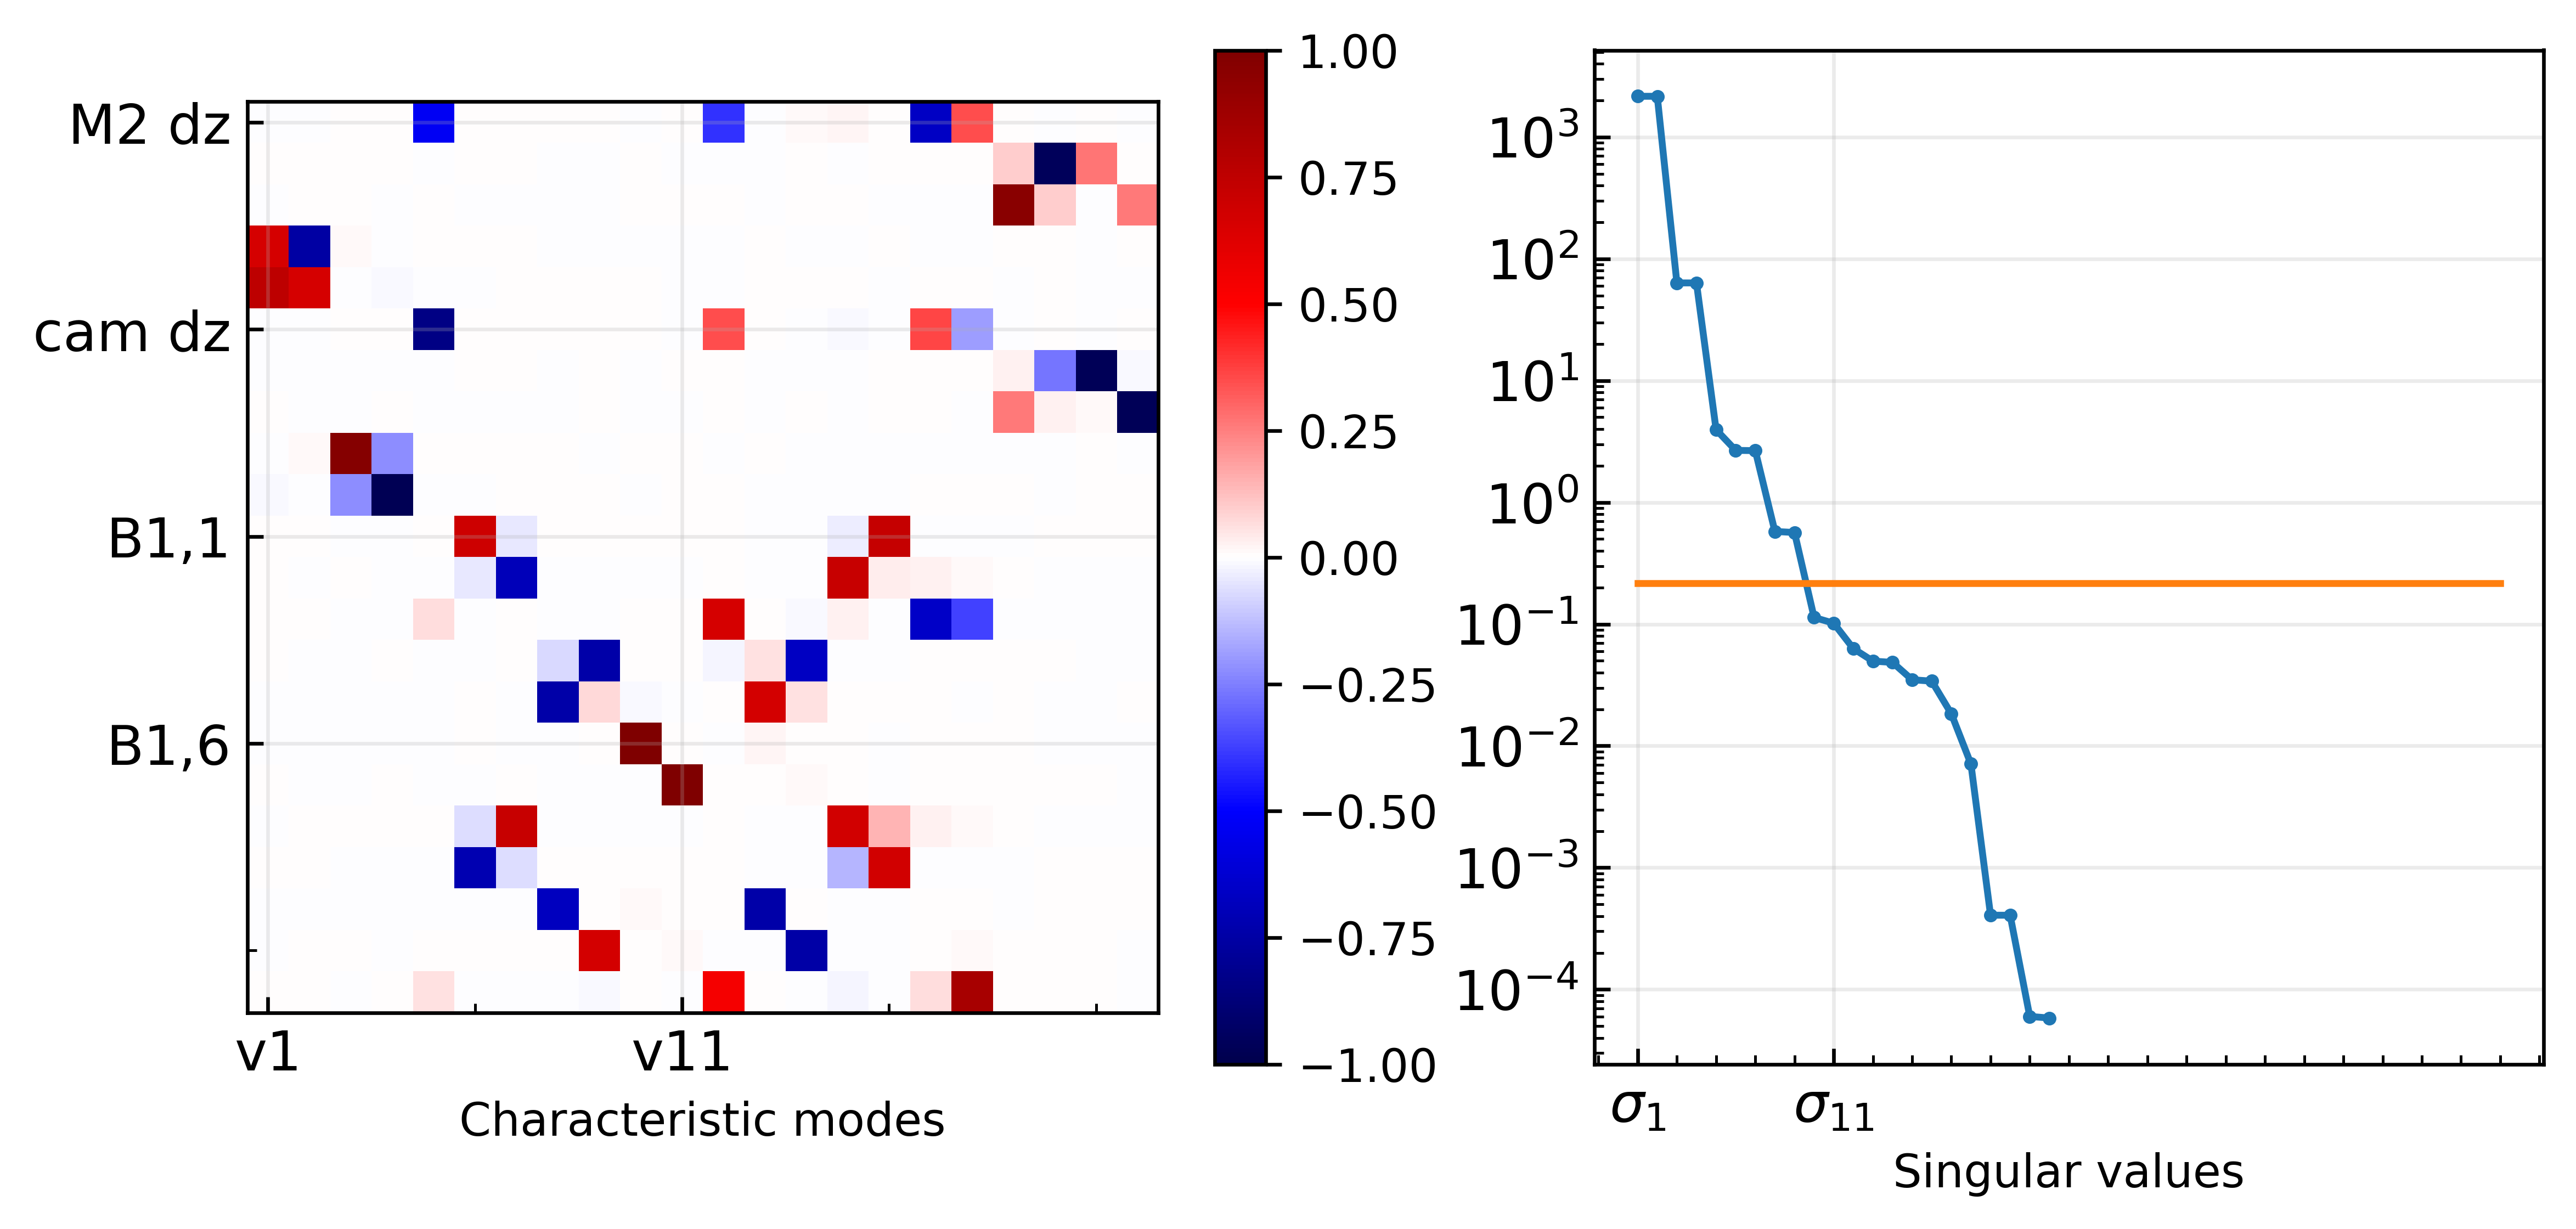

In [60]:
labels = ['M2 dz', 'M2 dx', 'M2 dy', 'M2 rx', 'M2 ry',
         'cam dz', 'cam dx', 'cam dy', 'cam rx', 'cam ry',
         'B1,1', 'B1,2', 'B1,3', 'B1,4', 'B1,5',
         'B1,6', 'B1,7', 'B1,8', 'B1,9', 'B1,10',
         'B1,11', 'B1,12', 'B1,13', 'B1,14', 'B1,15',
         'B1,16', 'B1,17', 'B1,18', 'B1,19', 'B1,20',
         'B2,1', 'B2,2', 'B2,3', 'B2,4', 'B2,5',
         'B2,6', 'B2,7', 'B2,8', 'B2,9', 'B2,10',
         'B2,11', 'B2,12', 'B2,13', 'B2,14', 'B2,15',
         'B2,16', 'B2,17', 'B2,18', 'B2,19', 'B2,20'
         ]

listOfDofs = list(range(0,16+1)) + list(range(30,34+1))
u, s, vh = np.linalg.svd(sensitivity_matrix[:,  listOfDofs], full_matrices=True)
v = vh.T

s_use22 = s
v_use22 = v

fig = plt.figure(figsize=(9, 4), dpi=600)
gs = gridspec.GridSpec(1,2, width_ratios=[1.2,1])
a0 = plt.subplot(gs[0])
a1 = plt.subplot(gs[1])

r = a0.imshow(v, cmap = 'seismic', vmin = -1, vmax = 1)

a0.set_yticks([0, 5, 10, 15], [labels[0], labels[5], labels[10], labels[15]])
a0.set_xticks([0, 10], ['v1', 'v11'])
fig.colorbar(r)
a0.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks
a0.xaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.yaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.set_xlabel('Characteristic modes')
a0.grid(alpha=0.25)
a0.tick_params(direction = 'in', labelsize=12)


a1.semilogy(s, '.-', markersize=4)
#truncate_index = 25
#cutoff =  0.85 * s[truncate_index - 1] / np.max(s)
#print(cutoff)
cutoff = 1.e-4
a1.semilogy(np.max(s)*cutoff*np.ones(45))
a1.set_xticks([0, 10], ['$\sigma_1$', '$\sigma_{11}$'])
a1.set_xlabel('Singular values')
a1.grid(alpha=0.25)
a1.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks

a1.xaxis.set_minor_locator(ticker.AutoMinorLocator())  # Auto set minor ticks on x-axis

fig.savefig('aos_charmodes_use22dof.png')

In [70]:
# M2 dz, Cam dz
labels_22dof = ['M2_dz', 'M2_dx', 'M2_dy', 'M2_rx', 'M2_ry',
          'Cam_dz', 'Cam_dx', 'Cam_dy', 'Cam_rx', 'Cam_ry',
          'B1_1', 'B1_2', 'B1_3', 'B1_4', 'B1_5',
          'B1_6', 'B1_7', 
          'B2_1', 'B2_2', 'B2_3', 'B2_4', 'B2_5']

_label_to_index = {name: i for i, name in enumerate(labels_22dof)}

def label_index(name):
    """Return the index of a given label."""
    return _label_to_index[name]


In [71]:
# print out the coefficients for Vmode_5 
vmode_5 = 5 - 1
print(v[:,vmode_5])

print(v[label_index('M2_dz'),vmode_5])
print(v[label_index('Cam_dz'),vmode_5])
print(v[label_index('B1_3'),vmode_5])
print(v[label_index('B2_5'),vmode_5])

# so its -0.53 * M2_dz -0.84 * Cam_dz 

[-5.30847709e-01 -2.39030482e-07  9.98732971e-09  7.17198740e-08
 -8.50254220e-08 -8.42520691e-01 -1.73846438e-08 -4.47466235e-09
  1.27620339e-07 -3.07448603e-07  3.76944879e-04 -1.98811157e-03
  6.77879926e-02 -9.78999056e-05 -2.90988019e-05 -6.80315540e-06
 -9.41942723e-07  5.64417020e-04 -2.01046076e-04 -4.73016826e-07
  1.22527026e-03  6.13059436e-02]
-0.5308477088278454
-0.8425206905100174
0.06778799260399675
0.06130594364681308


# use 30 DOFs

<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_593/974668157.py:44: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])
/tmp/ipykernel_593/974668157.py:44: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])


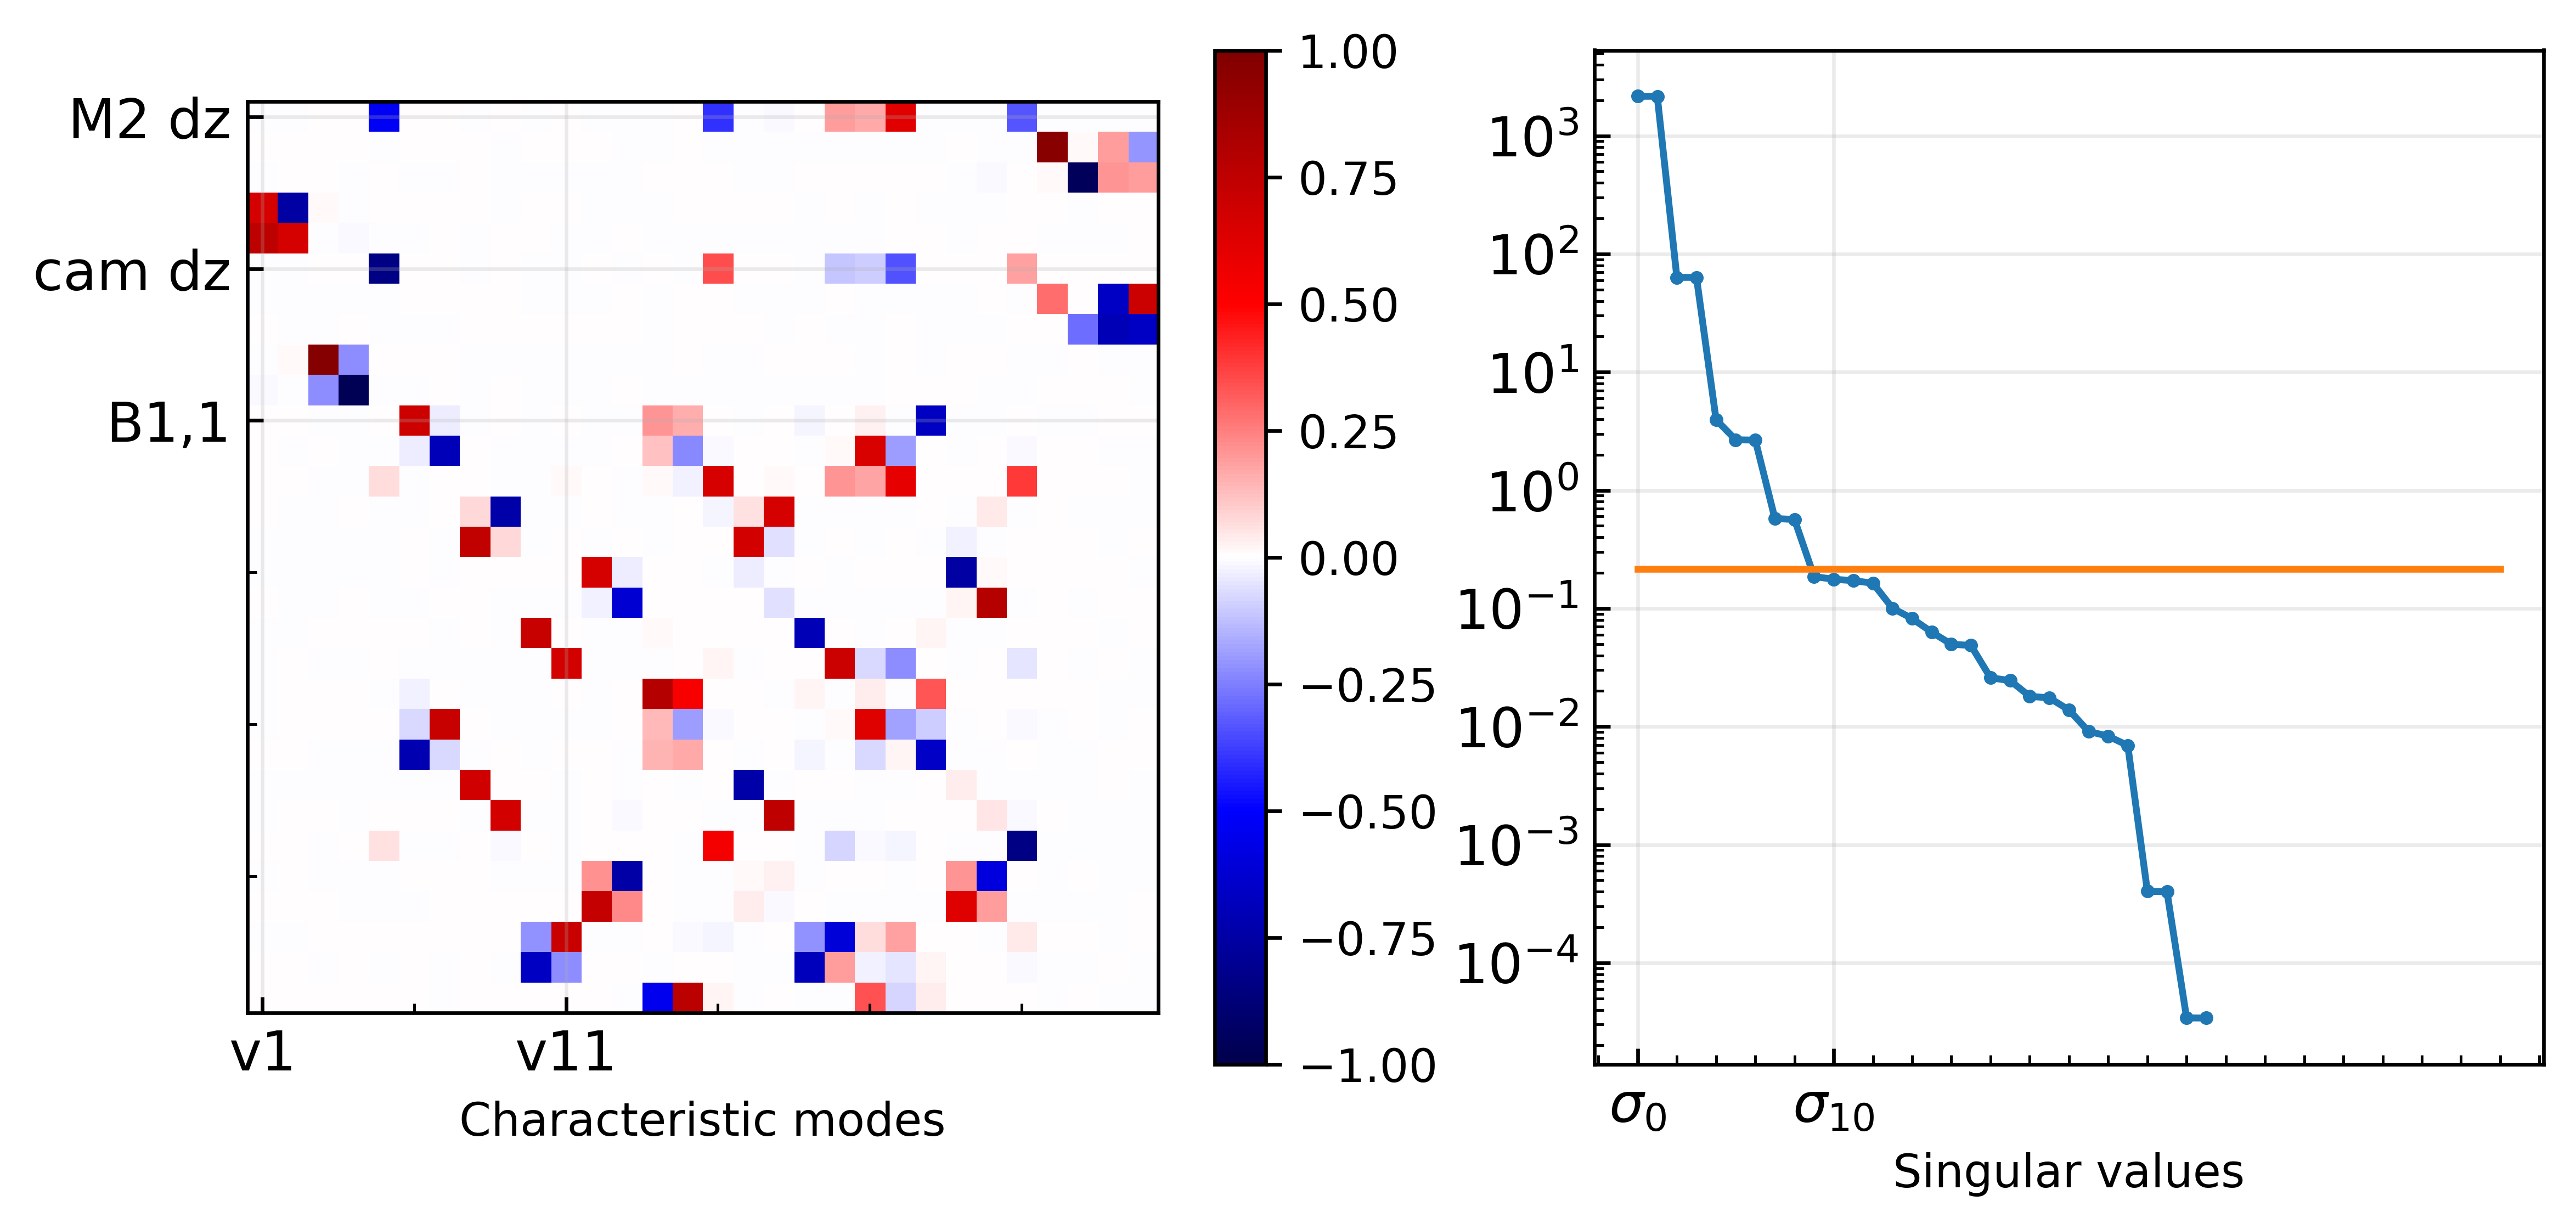

In [47]:
labels = ['M2 dz', 'M2 dx', 'M2 dy', 'M2 rx', 'M2 ry',
         'cam dz', 'cam dx', 'cam dy', 'cam rx', 'cam ry',
         'B1,1', 'B1,2', 'B1,3', 'B1,4', 'B1,5',
         'B1,6', 'B1,7', 'B1,8', 'B1,9', 'B1,10',
         'B1,11', 'B1,12', 'B1,13', 'B1,14', 'B1,15',
         'B1,16', 'B1,17', 'B1,18', 'B1,19', 'B1,20',
         'B2,1', 'B2,2', 'B2,3', 'B2,4', 'B2,5',
         'B2,6', 'B2,7', 'B2,8', 'B2,9', 'B2,10',
         'B2,11', 'B2,12', 'B2,13', 'B2,14', 'B2,15',
         'B2,16', 'B2,17', 'B2,18', 'B2,19', 'B2,20'
         ]

listOfDofs = list(range(0,19+1)) + list(range(30,39+1))
u, s, vh = np.linalg.svd(sensitivity_matrix[:,  listOfDofs], full_matrices=True)
v = vh.T

s_use30 = s
v_use30 = v

fig = plt.figure(figsize=(9, 4), dpi=600)
gs = gridspec.GridSpec(1,2, width_ratios=[1.2,1])
a0 = plt.subplot(gs[0])
a1 = plt.subplot(gs[1])

r = a0.imshow(v, cmap = 'seismic', vmin = -1, vmax = 1)

a0.set_yticks([0, 5, 10], [labels[0], labels[5], labels[10]])
a0.set_xticks([0, 10], ['v1', 'v11'])
fig.colorbar(r)
a0.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks
a0.xaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.yaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.set_xlabel('Characteristic modes')
a0.grid(alpha=0.25)
a0.tick_params(direction = 'in', labelsize=12)


a1.semilogy(s, '.-', markersize=4)
#truncate_index = 25
#cutoff =  0.85 * s[truncate_index - 1] / np.max(s)
#print(cutoff)
cutoff = 1.e-4
a1.semilogy(np.max(s)*cutoff*np.ones(45))
a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])
a1.set_xlabel('Singular values')
a1.grid(alpha=0.25)
a1.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks

a1.xaxis.set_minor_locator(ticker.AutoMinorLocator())  # Auto set minor ticks on x-axis

fig.savefig('aos_charmodes_use30dof.png')

# Use all 50 DOFs

<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_593/3703405323.py:43: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])
/tmp/ipykernel_593/3703405323.py:43: SyntaxWarning: invalid escape sequence '\s'
  a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])


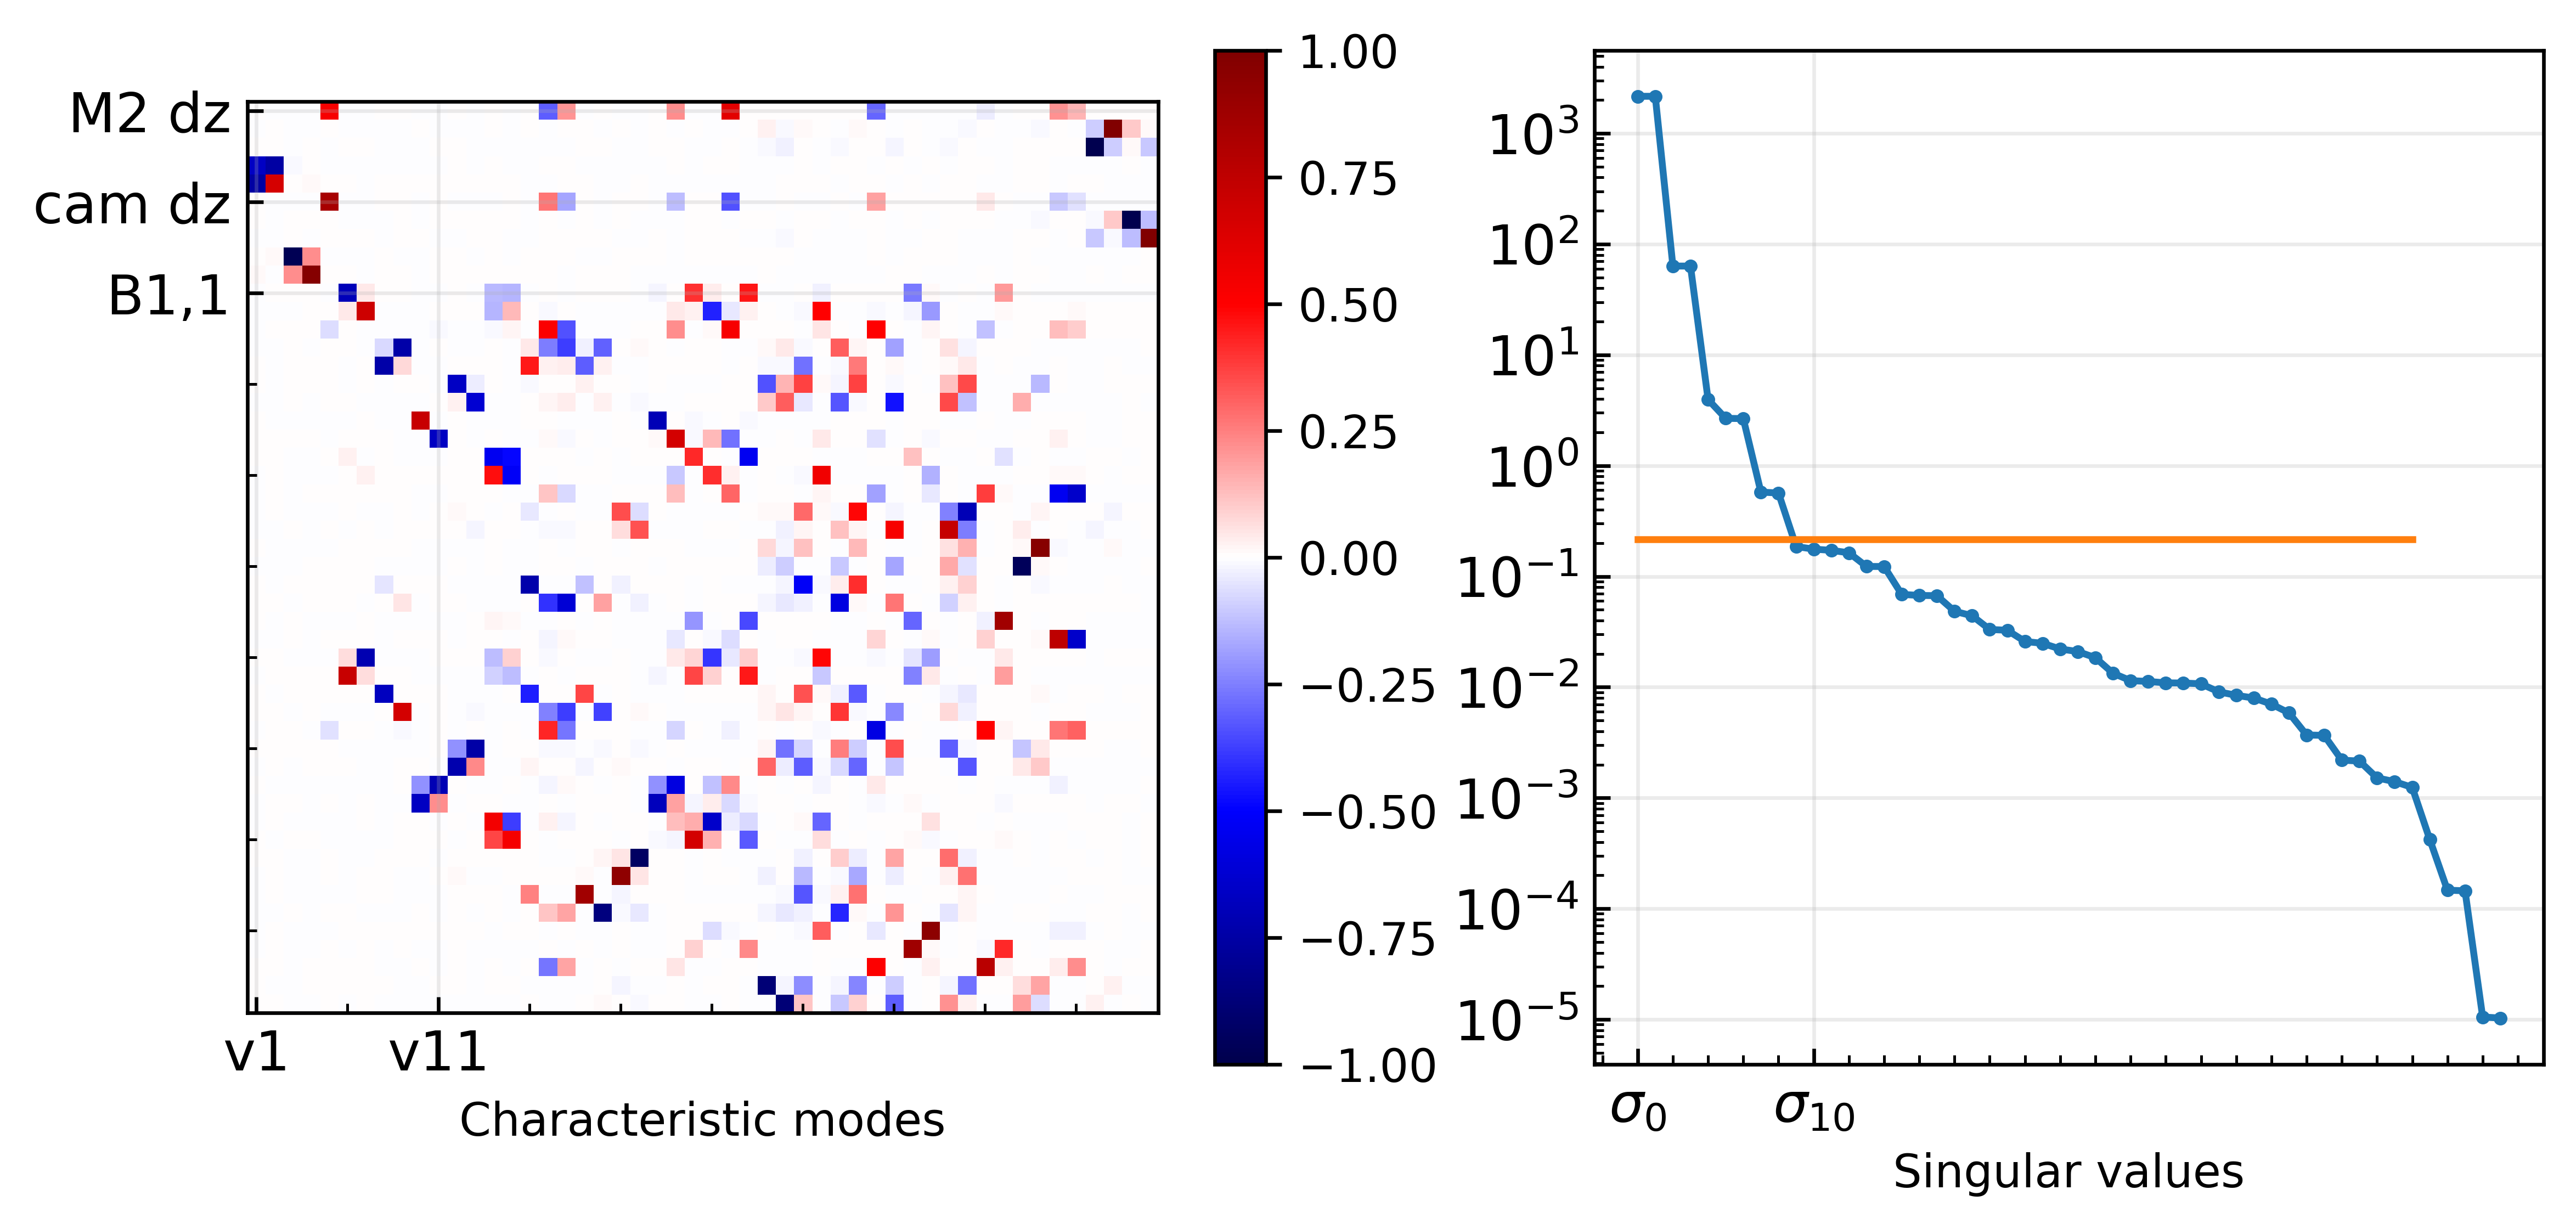

In [48]:
labels = ['M2 dz', 'M2 dx', 'M2 dy', 'M2 rx', 'M2 ry',
         'cam dz', 'cam dx', 'cam dy', 'cam rx', 'cam ry',
         'B1,1', 'B1,2', 'B1,3', 'B1,4', 'B1,5',
         'B1,6', 'B1,7', 'B1,8', 'B1,9', 'B1,10',
         'B1,11', 'B1,12', 'B1,13', 'B1,14', 'B1,15',
         'B1,16', 'B1,17', 'B1,18', 'B1,19', 'B1,20',
         'B2,1', 'B2,2', 'B2,3', 'B2,4', 'B2,5',
         'B2,6', 'B2,7', 'B2,8', 'B2,9', 'B2,10',
         'B2,11', 'B2,12', 'B2,13', 'B2,14', 'B2,15',
         'B2,16', 'B2,17', 'B2,18', 'B2,19', 'B2,20'
         ]
listOfCharModes = np.arange(50)
u, s, vh = np.linalg.svd(sensitivity_matrix[:,  listOfCharModes ], full_matrices=True)
v = vh.T

s_use50 = s
v_use50 = v

fig = plt.figure(figsize=(9, 4), dpi=600)
gs = gridspec.GridSpec(1,2, width_ratios=[1.2,1])
a0 = plt.subplot(gs[0])
a1 = plt.subplot(gs[1])

r = a0.imshow(v, cmap = 'seismic', vmin = -1, vmax = 1)

a0.set_yticks([0, 5, 10], [labels[0], labels[5], labels[10]])
a0.set_xticks([0, 10], ['v1', 'v11'])
fig.colorbar(r)
a0.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks
a0.xaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.yaxis.set_minor_locator(ticker.MultipleLocator(5))
a0.set_xlabel('Characteristic modes')
a0.grid(alpha=0.25)
a0.tick_params(direction = 'in', labelsize=12)


a1.semilogy(s, '.-', markersize=4)
#truncate_index = 25
#cutoff =  0.85 * s[truncate_index - 1] / np.max(s)
#print(cutoff)
cutoff = 1.e-4
a1.semilogy(np.max(s)*cutoff*np.ones(45))
a1.set_xticks([0, 10], ['$\sigma_0$', '$\sigma_{10}$'])
a1.set_xlabel('Singular values')
a1.grid(alpha=0.25)
a1.tick_params(direction='in', which='both', labelsize=12) # Apply to both major and minor ticks

a1.xaxis.set_minor_locator(ticker.AutoMinorLocator())  # Auto set minor ticks on x-axis
fig.savefig('aos_charmodes_use50dof.png')

## calculate the Zernike vector corresponding to a CMode

In [49]:
sensitivity_matrix.shape

(84, 50)

In [50]:
kCmode = 0
cmode_vec = v[:,kCmode]
print(cmode_vec)

[ 8.08448514e-09 -3.14009220e-06  2.73218178e-06 -6.56347644e-01
 -7.54375771e-01  1.29916739e-08  2.66411347e-08 -2.31618732e-08
  7.33776872e-03  8.43345126e-03 -5.76374949e-07 -5.84690952e-07
 -1.57473252e-08 -2.30170185e-07  2.23775544e-07  5.10278460e-06
 -3.73731691e-06  8.80521291e-08  6.49871631e-08  2.41918210e-09
 -1.83115371e-08 -4.33068894e-09 -7.80053453e-07 -1.29846377e-06
  1.03843024e-06 -9.87413533e-07  4.87774365e-07  1.56526855e-07
  4.33042586e-09 -1.54918882e-09  2.58611570e-08 -8.22285608e-10
  8.55067179e-08  7.24044145e-08 -2.29814632e-09  6.93344798e-07
 -1.75570119e-06  4.96546956e-10 -2.47310452e-10 -1.89619613e-10
  1.65890489e-10  1.96678570e-07 -3.90137563e-07 -2.67477829e-07
 -2.07541198e-07 -1.76528874e-10 -1.22180656e-10  8.79605188e-11
  1.50247076e-06  5.81374662e-07]


In [51]:
zhit_vec = sensitivity_matrix @ cmode_vec
print(zhit_vec.shape)
print(zhit_vec)

(84,)
[-2.44262678e+01 -6.28192336e+01 -8.99819057e+02  3.51236323e+02
 -4.03978156e+02 -3.20494945e+00 -2.75852099e+00  3.50971622e-02
  9.47501911e+00  6.46840602e-01 -6.35260544e-03  7.50766139e-02
  5.99283948e+00 -5.20338377e+00  8.99452282e-02  9.77084012e-02
  7.90597397e-03  2.13306809e-02  2.69091852e-01 -9.15532071e-03
 -7.55004392e-05 -3.51600888e+02  9.04066217e+02 -6.25519410e+01
  3.53155151e+02 -4.05643798e+02  3.39349057e+00  2.97078791e+00
  4.20631286e-01  6.64935560e-01 -9.24105139e+00 -8.97299128e-02
 -3.50332736e-03  6.12959293e+00 -5.35724337e+00 -7.77223965e-02
 -8.45891383e-02  6.50065448e-02 -2.54756442e-01  2.23459881e-02
  7.07814737e-04 -4.91828555e-03  3.51564363e+02 -9.04046347e+02
  6.24985236e+01  3.53173514e+02 -4.05648985e+02  3.39600499e+00
  2.98334593e+00 -4.35915351e-01 -6.53854831e-01  9.26097868e+00
  9.89242822e-02  6.62490097e-03  6.12398714e+00 -5.34357077e+00
 -7.16114942e-02 -8.51095522e-02 -7.29667015e-02  2.59024817e-01
 -1.60825062e-02  1

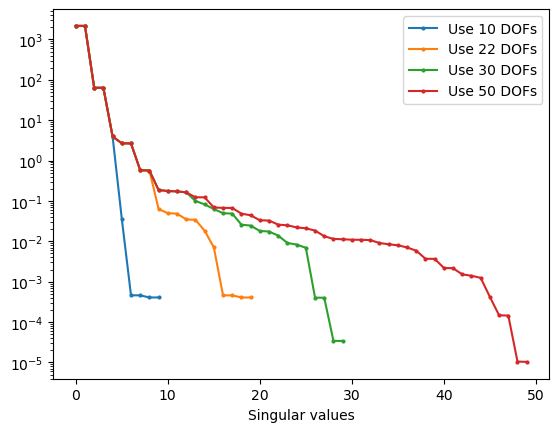

In [52]:
# compare Singular Values

f,ax = plt.subplots(1,1)
ax.semilogy(s_use10, '.-', markersize=4,label='Use 10 DOFs')

ax.semilogy(s_use22, '.-', markersize=4,label='Use 22 DOFs')
ax.semilogy(s_use30, '.-', markersize=4,label='Use 30 DOFs')

ax.semilogy(s_use50, '.-', markersize=4,label='Use 50 DOFs')
ax.set_xlabel('Singular values')
ax.legend()
f.savefig('aos_compare_nmodes.png')

# What Characteristic Modes have appreciable Z7 ?

In [53]:
listOfDofs10 = list(range(0,9+1))
listOfDofs20 = list(range(0,14+1)) + list(range(30,34+1))


In [54]:
iZ = 0 # assume this is Z4 ?
sensitivity_matrix[[iZ],  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]

array([-1.04893380e+00,  1.14631522e-03,  1.14652122e-03, -2.48896934e+02,
        2.48884446e+02, -1.66430996e+00, -1.30244475e-04, -1.30163167e-04,
        3.35798853e+01, -3.35793840e+01])

In [55]:
iZ = 1 # assume this is Z5 ?
sensitivity_matrix[[iZ],  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]

array([-3.01975034e-03,  2.65302087e-03,  2.65308618e-03, -6.40820086e+02,
        6.40816409e+02, -4.21744964e-03,  7.94335429e-05,  7.94782560e-05,
        3.30026856e+00, -3.30019768e+00])

In [56]:
iZ = 2 # assume this is Z6 ?
sensitivity_matrix[[iZ],  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]

array([-2.25931287e-07,  2.63145965e-03, -2.63177763e-03,  6.37807709e+02,
        6.37805344e+02, -3.44412612e-07,  7.12857200e-05, -7.13682580e-05,
       -3.20650914e+00, -3.20651639e+00])

In [57]:
iZ = 3 # assume this is Z7 ?
print(sensitivity_matrix[[iZ],  listOfDofs10])

iZ = 3 # assume this is Z7 ?
print(sensitivity_matrix[[iZ],  listOfDofs20])

[ 6.80120039e-03 -2.78658861e-05  2.22771612e-03 -5.36595646e+02
  1.28399200e+00  2.58160715e-02  9.76106254e-07 -1.96096769e-04
  9.83884027e-01  5.24983503e-01]
[ 6.80120039e-03 -2.78658861e-05  2.22771612e-03 -5.36595646e+02
  1.28399200e+00  2.58160715e-02  9.76106254e-07 -1.96096769e-04
  9.83884027e-01  5.24983503e-01 -3.29078800e-03 -4.90232175e-03
  8.84166290e-03  2.12732233e-03  1.47525229e-03  1.30241470e-02
  7.83735236e-03  1.15450778e-03 -2.17709578e-04  8.57338315e-03]


In [58]:
iZ = 4 # assume this is Z8 ?
sensitivity_matrix[[iZ],  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]

array([ 6.80022133e-03,  2.22810686e-03, -2.79749921e-05, -1.27696356e+00,
        5.36608086e+02,  2.58145665e-02, -1.95992470e-04,  9.51918447e-07,
       -5.25003324e-01, -9.83843212e-01])